<a href="https://colab.research.google.com/github/dolaprogram-design/affinetune/blob/main/Lens_Calibration_Analyzer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
# เซลล์ที่ 1: ติดตั้งไลบรารีเพิ่มเติมสำหรับอ่าน EXIF เชิงลึก (ExifTool / Piexif)
print("กำลังเตรียมระบบ...")
!pip install -q piexif pillow
print("พร้อมแล้ว!")

กำลังเตรียมระบบ...
พร้อมแล้ว!


In [8]:
import cv2
import piexif
from google.colab import files
import numpy as np
from PIL import Image

# 1. อัปโหลดภาพจากเครื่องของคุณขึ้นไปบน Colab
print("กรุณาเลือกไฟล์ภาพถ่ายทดสอบ (แนะนำไฟล์ JPEG จากกล้อง):")
uploaded = files.upload()

for filename in uploaded.keys():
  print(f"\nกำลังประมวลผลไฟล์: {filename}")

  # 2. อ่านค่า EXIF พื้นฐานด้วย Pillow & Piexif
  try:
    img_pil = Image.open(filename)
    exif_data = img_pil.info.get("exif")
    if exif_data:
      exif_dict = piexif.load(exif_data)
      print("--- ข้อมูล EXIF บางส่วน ---")
      # แสดงตัวอย่างข้อมูลรุ่นกล้อง (ถ้ามี)
      if "0th" in exif_dict and piexif.ImageIFD.Model in exif_dict["0th"]:
        model = exif_dict["0th"][piexif.ImageIFD.Model].decode("utf-8", "ignore")
        print(f"รุ่นกล้อง: {model}")
    else:
      print("ไม่พบข้อมูล EXIF ในภาพนี้ (อาจผ่านการแต่งหรือแชร์ผ่านโซเชียล)")
  except Exception as e:
    print(f"อ่าน EXIF ไม่สำเร็จ: {e}")

  # 3. ใช้ OpenCV คำนวณความคมชัด (Variance of Laplacian)
  # โหลดภาพด้วย OpenCV
  img_cv = cv2.imread(filename)
  gray = cv2.cvtColor(img_cv, cv2.COLOR_BGR2GRAY)

  # คำนวณ Laplacian หาขอบภาพ
  laplacian = cv2.Laplacian(gray, cv2.CV_64F)
  sharpness_score = np.var(laplacian)

  print(f"📈 คะแนนความคมชัด (Sharpness Score): {sharpness_score:.2f}")

  # ประเมินคุณภาพเบื้องต้น
  if sharpness_score < 100:
    print("เกณฑ์คุณภาพ: 🔴 เบลอ / หลุดโฟกัส")
  elif sharpness_score < 500:
    print("เกณฑ์คุณภาพ: 🟡 พอใช้")
  elif sharpness_score < 1500:
    print("เกณฑ์คุณภาพ: 🟢 คมชัดดี")
  else:
    print("เกณฑ์คุณภาพ: ⭐ คมชัดมาก (ยอดเยี่ยม)")

กรุณาเลือกไฟล์ภาพถ่ายทดสอบ (แนะนำไฟล์ JPEG จากกล้อง):


Saving PSJ_0887.NEF to PSJ_0887.NEF
Saving PSJ_0889.NEF to PSJ_0889.NEF
Saving PSJ_0890.NEF to PSJ_0890.NEF
Saving PSJ_0891.NEF to PSJ_0891.NEF

กำลังประมวลผลไฟล์: PSJ_0887.NEF
ไม่พบข้อมูล EXIF ในภาพนี้ (อาจผ่านการแต่งหรือแชร์ผ่านโซเชียล)
📈 คะแนนความคมชัด (Sharpness Score): 2279.70
เกณฑ์คุณภาพ: ⭐ คมชัดมาก (ยอดเยี่ยม)

กำลังประมวลผลไฟล์: PSJ_0889.NEF
ไม่พบข้อมูล EXIF ในภาพนี้ (อาจผ่านการแต่งหรือแชร์ผ่านโซเชียล)
📈 คะแนนความคมชัด (Sharpness Score): 2254.46
เกณฑ์คุณภาพ: ⭐ คมชัดมาก (ยอดเยี่ยม)

กำลังประมวลผลไฟล์: PSJ_0890.NEF
ไม่พบข้อมูล EXIF ในภาพนี้ (อาจผ่านการแต่งหรือแชร์ผ่านโซเชียล)
📈 คะแนนความคมชัด (Sharpness Score): 2378.33
เกณฑ์คุณภาพ: ⭐ คมชัดมาก (ยอดเยี่ยม)

กำลังประมวลผลไฟล์: PSJ_0891.NEF
ไม่พบข้อมูล EXIF ในภาพนี้ (อาจผ่านการแต่งหรือแชร์ผ่านโซเชียล)
📈 คะแนนความคมชัด (Sharpness Score): 2297.15
เกณฑ์คุณภาพ: ⭐ คมชัดมาก (ยอดเยี่ยม)


In [9]:
import piexif
from PIL import Image
from PIL.ExifTags import TAGS, GPSTAGS

# ใช้ไฟล์ล่าสุดที่ถูกโหลดเข้ามาในระบบ
target_file = filename
print(f"--- ดึงข้อมูล EXIF ทั้งหมดจากไฟล์: {target_file} ---\n")

try:
    img_pil = Image.open(target_file)
    exif_data = img_pil._getexif()

    if exif_data:
        exif_info = {}
        for tag_id, value in exif_data.items():
            tag_name = TAGS.get(tag_id, tag_id)
            exif_info[tag_name] = value

        # แสดงผลข้อมูลสำคัญ
        print("📸 [ ข้อมูลกล้องและการตั้งค่าหลัก ]")
        print(f"• ยี่ห้อกล้อง (Make): {exif_info.get('Make', 'ไม่ระบุ')}")
        print(f"• รุ่นกล้อง (Model): {exif_info.get('Model', 'ไม่ระบุ')}")
        print(f"• วันที่และเวลาที่ถ่าย (DateTimeOriginal): {exif_info.get('DateTimeOriginal', 'ไม่ระบุ')}")
        print(f"• ความเร็วชัตเตอร์ (ExposureTime): {exif_info.get('ExposureTime', 'ไม่ระบุ')} วินาที")

        # แปลงค่ารูรับแสง F-Number ให้เข้าใจง่าย
        f_number = exif_info.get('FNumber')
        print(f"• ค่ารูรับแสง (Aperture/F-Number): f/{float(f_number) if f_number else 'ไม่ระบุ'}")

        print(f"• ค่าความไวแสง (ISOSpeedRatings): {exif_info.get('ISOSpeedRatings', 'ไม่ระบุ')}")
        print(f"• ทางยาวโฟกัส (FocalLength): {exif_info.get('FocalLength', 'ไม่ระบุ')} mm")
        print(f"• เลนส์ที่ใช้ (LensModel): {exif_info.get('LensModel', 'ไม่ระบุ')}")
        print(f"• ซอฟต์แวร์ที่ใช้แต่งภาพ (Software): {exif_info.get('Software', 'ไม่ระบุ')}")

        print("\n🔍 [ ข้อมูล EXIF ดิบทั้งหมด ]")
        for key, val in sorted(exif_info.items()):
            # ซ่อนข้อมูลดิบประเภท bytes ยาวๆ เพื่อให้อ่านง่ายขึ้น
            if isinstance(val, bytes):
                val = f"<Bytes Data: {len(val)} bytes>"
            print(f"{key}: {val}")
    else:
        print("❌ ไม่พบข้อมูล EXIF เมทาดาตาในไฟล์ภาพนี้")
except Exception as e:
    print(f"เกิดข้อผิดพลาดในการดึงข้อมูล EXIF: {e}")

--- ดึงข้อมูล EXIF ทั้งหมดจากไฟล์: PSJ_0891.NEF ---

เกิดข้อผิดพลาดในการดึงข้อมูล EXIF: 'TiffImageFile' object has no attribute '_getexif'


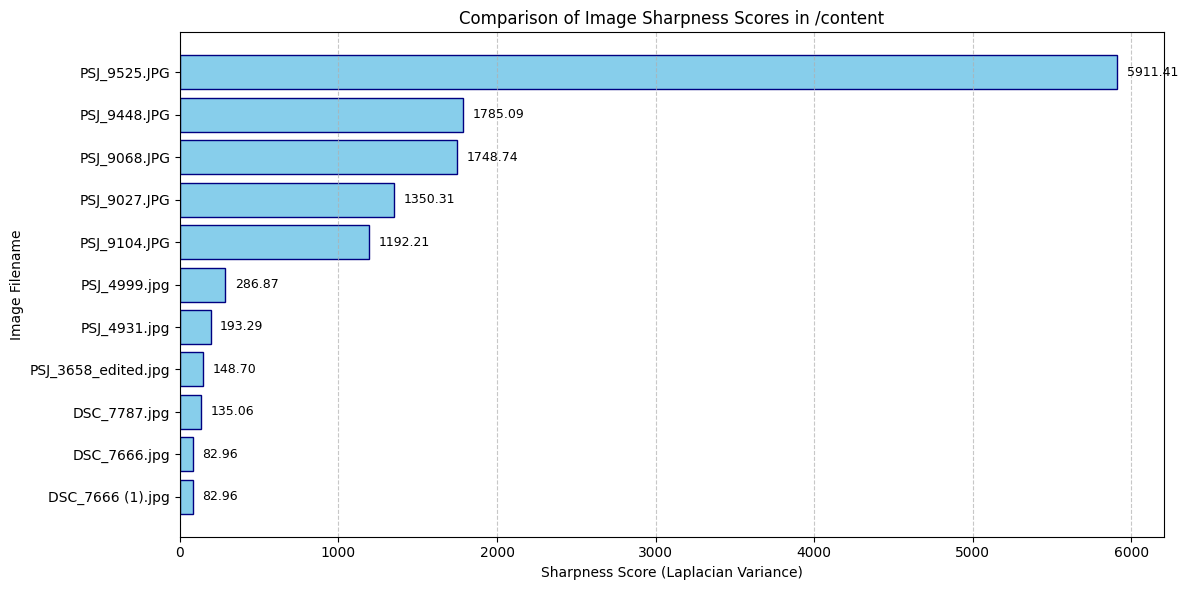

In [10]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

# นามสกุลไฟล์รูปภาพที่รองรับ
valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp')

image_scores = {}
folder_path = '/content'

# วนลูปอ่านทุกไฟล์ในโฟลเดอร์
for file_name in os.listdir(folder_path):
    if file_name.lower().endswith(valid_extensions):
        file_path = os.path.join(folder_path, file_name)
        try:
            # โหลดรูปภาพแบบเกรย์สเกล
            img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                # คำนวณหาความคมชัดด้วย Laplacian Variance
                laplacian_var = cv2.Laplacian(img, cv2.CV_64F).var()
                image_scores[file_name] = laplacian_var
        except Exception as e:
            print(f"Error processing {file_name}: {e}")

if image_scores:
    # จัดเรียงลำดับตามคะแนนความคมชัดจากน้อยไปมาก
    sorted_scores = sorted(image_scores.items(), key=lambda x: x[1])
    names = [item[0] for item in sorted_scores]
    scores = [item[1] for item in sorted_scores]

    # สร้างกราฟเปรียบเทียบ (ใช้ภาษาอังกฤษเพื่อหลีกเลี่ยงปัญหาฟอนต์ไทย)
    fig, ax = plt.subplots(figsize=(12, 6))
    bars = ax.barh(names, scores, color='skyblue', edgecolor='navy')

    # ตกแต่งกราฟ
    ax.set_xlabel('Sharpness Score (Laplacian Variance)')
    ax.set_ylabel('Image Filename')
    ax.set_title('Comparison of Image Sharpness Scores in /content')
    ax.grid(axis='x', linestyle='--', alpha=0.7)

    # แสดงคะแนนบนแท่งกราฟ
    for bar in bars:
        width = bar.get_width()
        ax.text(width + (max(scores) * 0.01), bar.get_y() + bar.get_height()/2,
                f'{width:.2f}',
                va='center', ha='left', fontsize=9, color='black')

    plt.tight_layout()
    plt.show()
else:
    print("❌ No image files found in /content")

In [11]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from PIL.ExifTags import TAGS

valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp')
folder_path = '/content'

data_records = []

# ค้นหาและดึงข้อมูลของแต่ละภาพ
for file_name in os.listdir(folder_path):
    if file_name.lower().endswith(valid_extensions):
        file_path = os.path.join(folder_path, file_name)

        # 1. คำนวณความคมชัด
        sharpness_score = None
        try:
            img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                sharpness_score = float(cv2.Laplacian(img, cv2.CV_64F).var())
        except Exception as e:
            pass

        # 2. ดึงค่า ISO
        iso_value = None
        try:
            img_pil = Image.open(file_path)
            exif_data = img_pil._getexif()
            if exif_data:
                for tag_id, value in exif_data.items():
                    tag_name = TAGS.get(tag_id, tag_id)
                    if tag_name == 'ISOSpeedRatings':
                        iso_value = int(value)
                        break
        except Exception as e:
            pass

        if sharpness_score is not None:
            data_records.append({
                'Filename': file_name,
                'Sharpness': sharpness_score,
                'ISO': iso_value if iso_value is not None else "No EXIF"
            })

# แปลงเป็น DataFrame และแสดงผล
df_comparison = pd.DataFrame(data_records)
display(df_comparison.sort_values(by='Sharpness', ascending=False))

,Filename,Sharpness,ISO
7,PSJ_9525.JPG,5911.405071,1600
1,PSJ_9448.JPG,1785.087024,800
3,PSJ_9068.JPG,1748.739547,800
6,PSJ_9027.JPG,1350.308137,800
9,PSJ_9104.JPG,1192.207693,800
0,PSJ_4999.jpg,286.871502,400
10,PSJ_4931.jpg,193.291149,400
2,PSJ_3658_edited.jpg,148.702911,31
8,DSC_7787.jpg,135.060537,800
5,DSC_7666.jpg,82.964822,800


/tmp/ipykernel_65003/3269395501.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(df_plot['Filename'], rotation=45, ha='right')


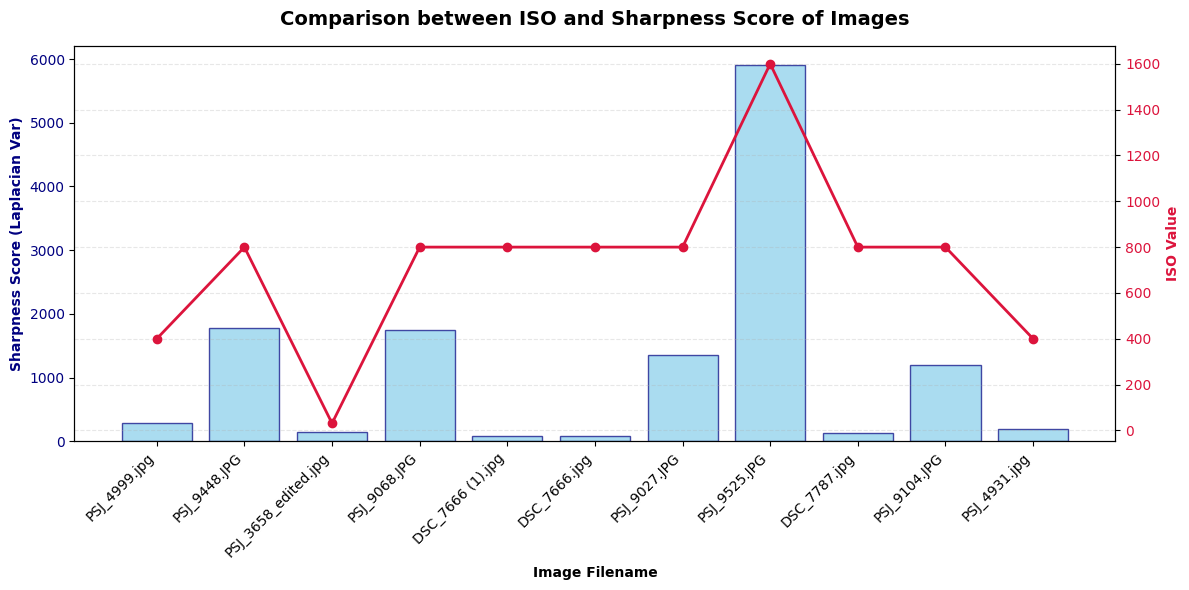

In [12]:
# กรองเอาเฉพาะข้อมูลที่มีค่า ISO จริงเพื่อนำมาวาดกราฟวิเคราะห์
df_plot = df_comparison[df_comparison['ISO'] != 'No EXIF'].copy()
if not df_plot.empty:
    df_plot['ISO'] = df_plot['ISO'].astype(int)

    # วาดกราฟเปรียบเทียบ
    fig, ax1 = plt.subplots(figsize=(12, 6))

    # กราฟแท่งแสดงความคมชัด (แกนซ้าย)
    color = 'skyblue'
    ax1.set_xlabel('Image Filename', fontweight='bold')
    ax1.set_ylabel('Sharpness Score (Laplacian Var)', color='navy', fontweight='bold')
    bars = ax1.bar(df_plot['Filename'], df_plot['Sharpness'], color=color, edgecolor='navy', alpha=0.7, label='Sharpness')
    ax1.tick_params(axis='y', labelcolor='navy')
    ax1.set_xticklabels(df_plot['Filename'], rotation=45, ha='right')

    # กราฟเส้นแสดงค่า ISO (แกนขวา)
    ax2 = ax1.twinx()
    color = 'crimson'
    ax2.set_ylabel('ISO Value', color=color, fontweight='bold')
    line = ax2.plot(df_plot['Filename'], df_plot['ISO'], color=color, marker='o', linewidth=2, label='ISO')
    ax2.tick_params(axis='y', labelcolor=color)

    plt.title('Comparison between ISO and Sharpness Score of Images', fontsize=14, fontweight='bold', pad=15)
    fig.tight_layout()
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.show()
else:
    print("ไม่พบข้อมูล EXIF ISO ในภาพถ่ายสำหรับนำมาวาดกราฟเปรียบเทียบ")

In [13]:
# กรองเฉพาะภาพที่มีค่า ISO จริง
df_valid_iso = df_comparison[df_comparison['ISO'] != 'No EXIF'].copy()
df_valid_iso['ISO'] = df_valid_iso['ISO'].astype(int)

# คำนวณค่าเฉลี่ยความคมชัดแยกตามกลุ่ม ISO
df_iso_group = df_valid_iso.groupby('ISO')['Sharpness'].agg(['mean', 'count']).reset_index()
df_iso_group.columns = ['ISO', 'Average Sharpness', 'Image Count']

# แสดงผลตารางสรุป
print("📊 ตารางสรุปค่าเฉลี่ยความคมชัดแยกตามระดับ ISO:")
display(df_iso_group.sort_values(by='ISO'))

📊 ตารางสรุปค่าเฉลี่ยความคมชัดแยกตามระดับ ISO:


,ISO,Average Sharpness,Image Count
0,31,148.702911,1
1,400,240.081326,2
2,800,911.047512,7
3,1600,5911.405071,1


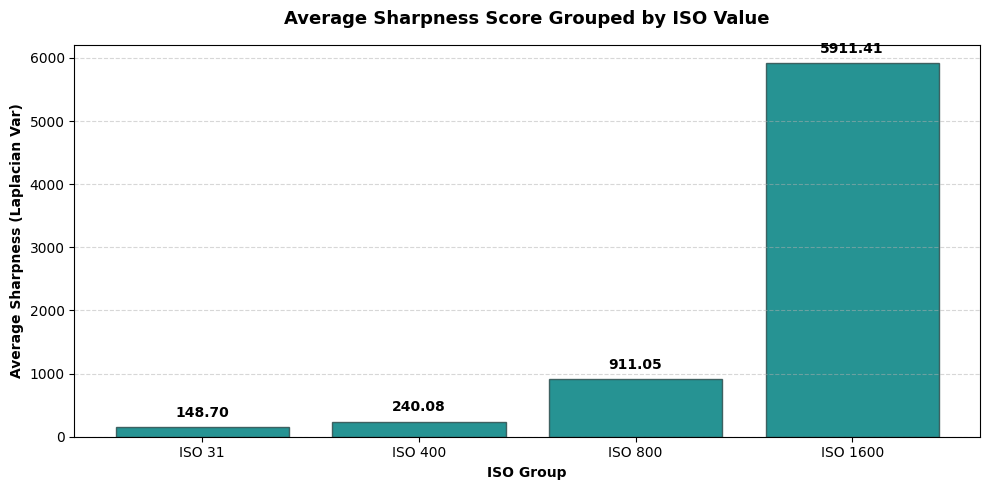

In [14]:
import matplotlib.pyplot as plt

# สร้างกราฟแสดงความสัมพันธ์ของค่าเฉลี่ยความคมชัดในแต่ละกลุ่ม ISO
fig, ax = plt.subplots(figsize=(10, 5))

# แปลงประเภท ISO เป็น String เพื่อแสดงผลบนแกน X เป็นหมวดหมู่ (Category)
x_labels = [f"ISO {int(x)}" for x in df_iso_group['ISO']]
bars = ax.bar(x_labels, df_iso_group['Average Sharpness'], color='teal', edgecolor='darkslategrey', alpha=0.85)

# ตกแต่งรายละเอียดกราฟ
ax.set_ylabel('Average Sharpness (Laplacian Var)', fontweight='bold')
ax.set_xlabel('ISO Group', fontweight='bold')
ax.set_title('Average Sharpness Score Grouped by ISO Value', fontsize=13, fontweight='bold', pad=15)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# แสดงตัวเลขค่าเฉลี่ยเหนือแท่งกราฟ
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + (max(df_iso_group['Average Sharpness']) * 0.02),
            f'{height:.2f}',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [15]:
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from PIL.ExifTags import TAGS

valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp')
folder_path = '/content'
focal_sharpness_data = []

for file_name in os.listdir(folder_path):
    if file_name.lower().endswith(valid_extensions):
        file_path = os.path.join(folder_path, file_name)

        # 1. คำนวณความคมชัด (Laplacian Variance)
        sharpness_score = None
        try:
            img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                sharpness_score = float(cv2.Laplacian(img, cv2.CV_64F).var())
        except:
            pass

        # 2. ดึงค่า Focal Length จาก EXIF
        focal_length = None
        try:
            img_pil = Image.open(file_path)
            exif_data = img_pil._getexif()
            if exif_data:
                for tag_id, value in exif_data.items():
                    tag_name = TAGS.get(tag_id, tag_id)
                    if tag_name == 'FocalLength':
                        focal_length = float(value)
                        break
        except:
            pass

        if sharpness_score is not None:
            focal_sharpness_data.append({
                'Filename': file_name,
                'FocalLength_mm': focal_length if focal_length is not None else "No EXIF",
                'Sharpness': sharpness_score
            })

# แปลงเป็น DataFrame และคัดเลือกภาพที่มีข้อมูลพารามิเตอร์ครบ
df_focal = pd.DataFrame(focal_sharpness_data)
df_focal_valid = df_focal[df_focal['FocalLength_mm'] != 'No EXIF'].copy()
df_focal_valid['FocalLength_mm'] = df_focal_valid['FocalLength_mm'].astype(float)

print("📊 ตารางความสัมพันธ์ระหว่าง Focal Length และ Sharpness:")
display(df_focal_valid.sort_values(by='FocalLength_mm'))

📊 ตารางความสัมพันธ์ระหว่าง Focal Length และ Sharpness:


,Filename,FocalLength_mm,Sharpness
2,PSJ_3658_edited.jpg,34.0,148.702911
8,DSC_7787.jpg,150.0,135.060537
9,PSJ_9104.JPG,150.0,1192.207693
4,DSC_7666 (1).jpg,200.0,82.964822
5,DSC_7666.jpg,200.0,82.964822
1,PSJ_9448.JPG,230.0,1785.087024
7,PSJ_9525.JPG,240.0,5911.405071
3,PSJ_9068.JPG,310.0,1748.739547
0,PSJ_4999.jpg,320.0,286.871502
6,PSJ_9027.JPG,440.0,1350.308137


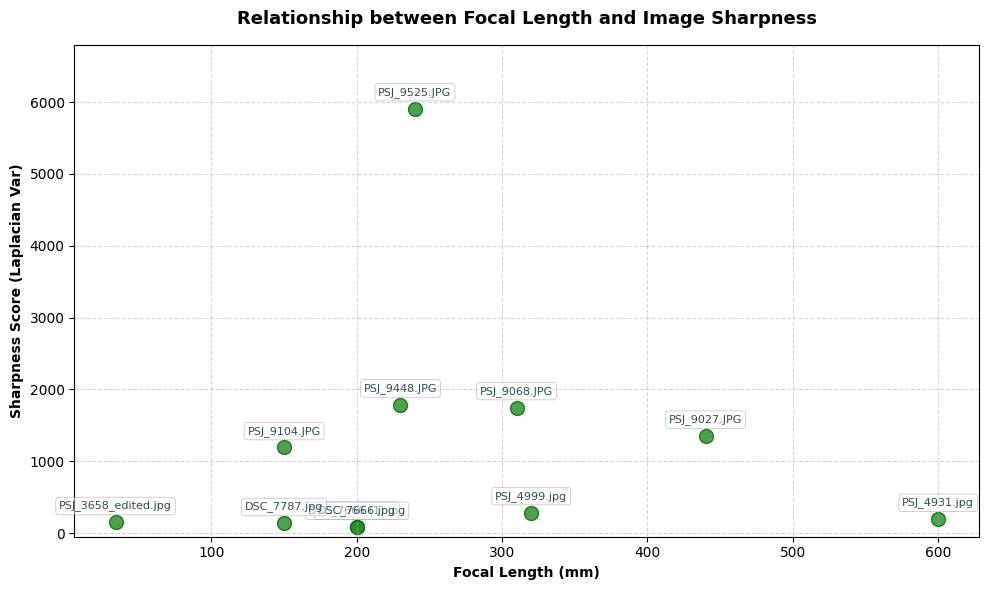

In [16]:
# สร้างกราฟแสดงความสัมพันธ์ในรูปแบบ Scatter Plot พร้อมระบุชื่อไฟล์
if not df_focal_valid.empty:
    plt.figure(figsize=(10, 6))

    # วาดจุดข้อมูล
    plt.scatter(df_focal_valid['FocalLength_mm'], df_focal_valid['Sharpness'], color='forestgreen', s=100, alpha=0.8, edgecolors='darkgreen')

    # ใส่ชื่อไฟล์กำกับแต่ละจุดข้อมูล
    for i, row in df_focal_valid.iterrows():
        plt.annotate(row['Filename'],
                     (row['FocalLength_mm'], row['Sharpness']),
                     textcoords="offset points",
                     xytext=(0,10),
                     ha='center',
                     fontsize=8,
                     color='darkslategrey',
                     bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.5, ec="gray", lw=0.5))

    plt.title('Relationship between Focal Length and Image Sharpness', fontsize=13, fontweight='bold', pad=15)
    plt.xlabel('Focal Length (mm)', fontweight='bold')
    plt.ylabel('Sharpness Score (Laplacian Var)', fontweight='bold')
    plt.grid(True, linestyle='--', alpha=0.5)

    # เพิ่มระยะขอบด้านบนของกราฟให้มีที่พอสำหรับ Annotation
    y_limit_max = df_focal_valid['Sharpness'].max() * 1.15
    plt.ylim(bottom=-50, top=y_limit_max)

    plt.tight_layout()
    plt.show()
else:
    print("ไม่พบข้อมูล Focal Length ในภาพสำหรับสร้างกราฟ")

In [17]:
import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from PIL.ExifTags import TAGS

valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp')
folder_path = '/content'
shutter_sharpness_data = []

for file_name in os.listdir(folder_path):
    if file_name.lower().endswith(valid_extensions):
        file_path = os.path.join(folder_path, file_name)

        # 1. คำนวณความคมชัด (Laplacian Variance)
        sharpness_score = None
        try:
            img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                sharpness_score = float(cv2.Laplacian(img, cv2.CV_64F).var())
        except:
            pass

        # 2. ดึงค่า ExposureTime จาก EXIF
        exposure_time = None
        try:
            img_pil = Image.open(file_path)
            exif_data = img_pil._getexif()
            if exif_data:
                for tag_id, value in exif_data.items():
                    tag_name = TAGS.get(tag_id, tag_id)
                    if tag_name == 'ExposureTime':
                        exposure_time = float(value)
                        break
        except:
            pass

        if sharpness_score is not None:
            shutter_sharpness_data.append({
                'Filename': file_name,
                'ExposureTime_sec': exposure_time if exposure_time is not None else "No EXIF",
                'Sharpness': sharpness_score
            })

# แปลงเป็น DataFrame และคัดเลือกภาพที่มีข้อมูล EXIF ครบถ้วน
df_shutter = pd.DataFrame(shutter_sharpness_data)
df_shutter_valid = df_shutter[df_shutter['ExposureTime_sec'] != 'No EXIF'].copy()
df_shutter_valid['ExposureTime_sec'] = df_shutter_valid['ExposureTime_sec'].astype(float)

# คำนวณความเร็วชัตเตอร์ในรูปแบบตัวเศษส่วน (เช่น 1/800) เพื่อความสะดวกในการอ่าน
def format_shutter(speed):
    if speed == 0:
        return "0"
    if speed >= 1:
        return f"{speed:.1f}s"
    return f"1/{int(round(1/speed))}"

df_shutter_valid['ShutterSpeed_Formatted'] = df_shutter_valid['ExposureTime_sec'].apply(format_shutter)

print("📊 ตารางความสัมพันธ์ระหว่าง ความเร็วชัตเตอร์ (Shutter Speed) และความคมชัด (Sharpness):")
display(df_shutter_valid.sort_values(by='ExposureTime_sec'))

📊 ตารางความสัมพันธ์ระหว่าง ความเร็วชัตเตอร์ (Shutter Speed) และความคมชัด (Sharpness):


,Filename,ExposureTime_sec,Sharpness,ShutterSpeed_Formatted
5,DSC_7666.jpg,0.000500,82.964822,1/2000
4,DSC_7666 (1).jpg,0.000500,82.964822,1/2000
0,PSJ_4999.jpg,0.001000,286.871502,1/1000
3,PSJ_9068.JPG,0.001000,1748.739547,1/1000
10,PSJ_4931.jpg,0.001250,193.291149,1/800
9,PSJ_9104.JPG,0.001250,1192.207693,1/800
6,PSJ_9027.JPG,0.001563,1350.308137,1/640
1,PSJ_9448.JPG,0.003125,1785.087024,1/320
7,PSJ_9525.JPG,0.004000,5911.405071,1/250
8,DSC_7787.jpg,0.010000,135.060537,1/100


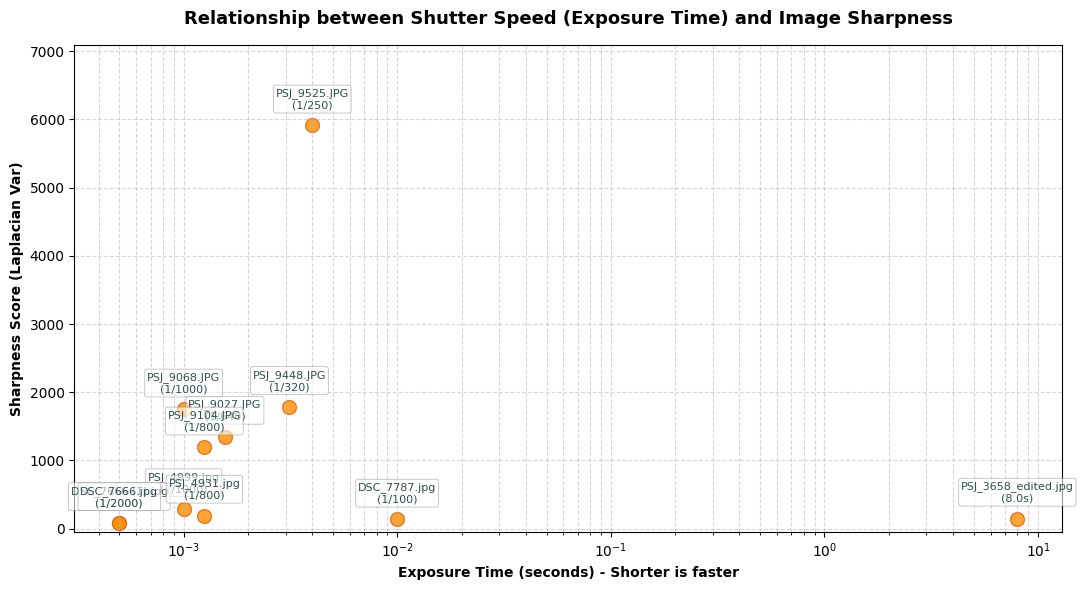

In [18]:
# สร้างกราฟ Scatter Plot แสดงความสัมพันธ์
if not df_shutter_valid.empty:
    plt.figure(figsize=(11, 6))

    # วาดจุดกราฟ
    plt.scatter(df_shutter_valid['ExposureTime_sec'], df_shutter_valid['Sharpness'], color='darkorange', s=100, alpha=0.8, edgecolors='chocolate')

    # ใส่ป้ายกำกับชื่อไฟล์และความเร็วชัตเตอร์
    for i, row in df_shutter_valid.iterrows():
        label = f"{row['Filename']}\n({row['ShutterSpeed_Formatted']})"
        plt.annotate(label,
                     (row['ExposureTime_sec'], row['Sharpness']),
                     textcoords="offset points",
                     xytext=(0,12),
                     ha='center',
                     fontsize=8,
                     color='darkslategrey',
                     bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.6, ec="gray", lw=0.5))

    plt.title('Relationship between Shutter Speed (Exposure Time) and Image Sharpness', fontsize=13, fontweight='bold', pad=15)
    plt.xlabel('Exposure Time (seconds) - Shorter is faster', fontweight='bold')
    plt.ylabel('Sharpness Score (Laplacian Var)', fontweight='bold')
    plt.xscale('log') # ใช้สเกล Log สำหรับแกน X เพื่อให้อ่านค่าความเร็วชัตเตอร์ง่ายขึ้น
    plt.grid(True, which="both", linestyle='--', alpha=0.5)

    # ปรับแต่งระยะขอบแกน Y
    y_limit_max = df_shutter_valid['Sharpness'].max() * 1.2
    plt.ylim(bottom=-50, top=y_limit_max)

    plt.tight_layout()
    plt.show()
else:
    print("ไม่พบข้อมูลความเร็วชัตเตอร์ในภาพเพื่อสร้างกราฟ")

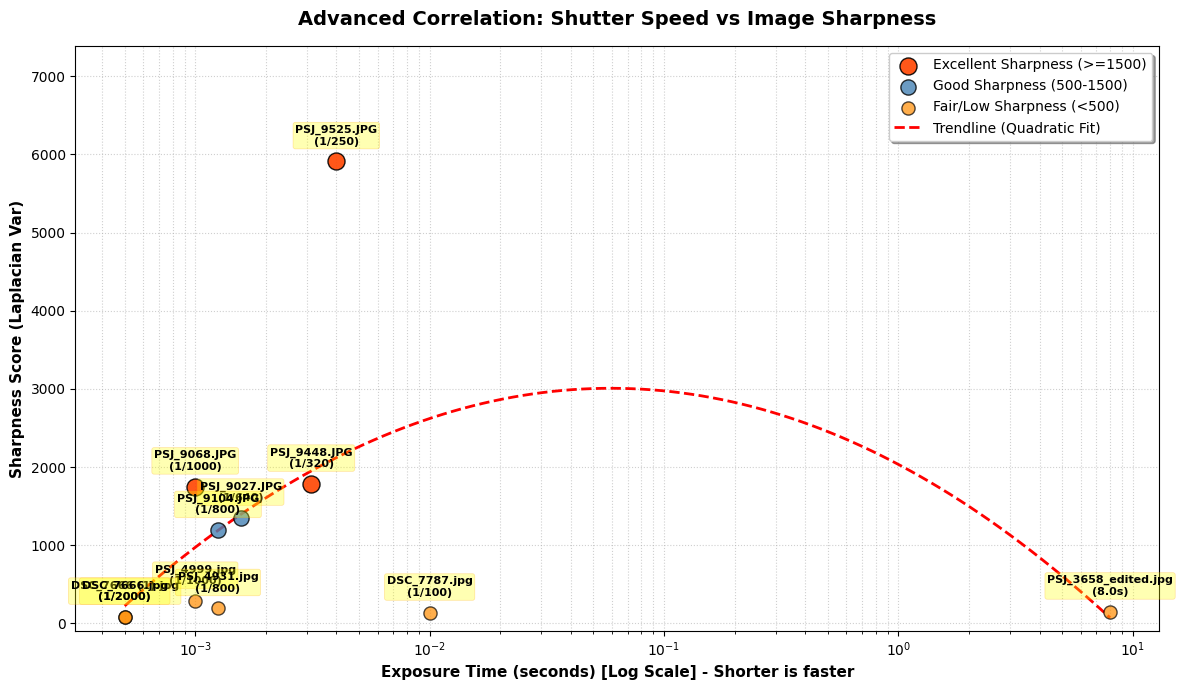

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

if not df_shutter_valid.empty:
    plt.figure(figsize=(12, 7))

    # แยกกลุ่มข้อมูลเพื่อใช้สีที่แตกต่างแสดงระดับความคมชัด
    high_sharp = df_shutter_valid[df_shutter_valid['Sharpness'] >= 1500]
    med_sharp = df_shutter_valid[(df_shutter_valid['Sharpness'] < 1500) & (df_shutter_valid['Sharpness'] >= 500)]
    low_sharp = df_shutter_valid[df_shutter_valid['Sharpness'] < 500]

    # 1. พล็อตจุดแยกสีตามกลุ่มคุณภาพ
    plt.scatter(high_sharp['ExposureTime_sec'], high_sharp['Sharpness'], color='#FF4500', s=150, alpha=0.9, edgecolors='black', label='Excellent Sharpness (>=1500)', zorder=3)
    plt.scatter(med_sharp['ExposureTime_sec'], med_sharp['Sharpness'], color='#4682B4', s=120, alpha=0.8, edgecolors='black', label='Good Sharpness (500-1500)', zorder=3)
    plt.scatter(low_sharp['ExposureTime_sec'], low_sharp['Sharpness'], color='#FF8C00', s=90, alpha=0.7, edgecolors='black', label='Fair/Low Sharpness (<500)', zorder=3)

    # 2. ทำ Curve Fitting เพื่อวาดเส้นแนวโน้มเชิงสถิติ (Logarithmic space trendline)
    x_sorted = np.sort(df_shutter_valid['ExposureTime_sec'].values)
    x_log = np.log10(df_shutter_valid['ExposureTime_sec'].values)
    y = df_shutter_valid['Sharpness'].values

    # ใช้ฟังก์ชัน Polynomial ดีกรี 2 ใน Log-space เพื่อหาจุดโค้งมนของแนวโน้ม
    poly_coefs = np.polyfit(x_log, y, 2)
    poly_func = np.poly1d(poly_coefs)

    x_trend = np.logspace(np.log10(x_sorted.min()), np.log10(x_sorted.max()), 100)
    y_trend = poly_func(np.log10(x_trend))

    # จำกัดไม่ให้เส้นแนวโน้มตกลงไปต่ำกว่า 0
    y_trend = np.clip(y_trend, 0, None)

    plt.plot(x_trend, y_trend, color='red', linestyle='--', linewidth=2, label='Trendline (Quadratic Fit)', zorder=2)

    # 3. ใส่ชื่อไฟล์กำกับแต่ละจุดข้อมูล
    for i, row in df_shutter_valid.iterrows():
        label = f"{row['Filename']}\n({row['ShutterSpeed_Formatted']})"
        plt.annotate(label,
                     (row['ExposureTime_sec'], row['Sharpness']),
                     textcoords="offset points",
                     xytext=(0,12),
                     ha='center',
                     fontsize=8,
                     fontweight='bold',
                     color='black',
                     bbox=dict(boxstyle="round,pad=0.2", fc="yellow", alpha=0.3, ec="orange", lw=0.5))

    plt.title('Advanced Correlation: Shutter Speed vs Image Sharpness', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Exposure Time (seconds) [Log Scale] - Shorter is faster', fontweight='bold', fontsize=11)
    plt.ylabel('Sharpness Score (Laplacian Var)', fontweight='bold', fontsize=11)

    plt.xscale('log')
    plt.grid(True, which="both", linestyle=':', alpha=0.6)
    plt.legend(loc='upper right', frameon=True, shadow=True)

    # ปรับแต่งระดับขอบกราฟ
    plt.ylim(bottom=-100, top=df_shutter_valid['Sharpness'].max() * 1.25)

    plt.tight_layout()
    plt.show()
else:
    print("ไม่พบข้อมูลที่ต้องการเปรียบเทียบ")

In [20]:
import os
import cv2
import numpy as np
import pandas as pd
from PIL import Image
from PIL.ExifTags import TAGS

valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.tiff', '.webp')
folder_path = '/content'

report_data = []

for file_name in os.listdir(folder_path):
    if file_name.lower().endswith(valid_extensions):
        file_path = os.path.join(folder_path, file_name)

        # 1. คำนวณความคมชัด
        sharpness_score = None
        try:
            img = cv2.imread(file_path, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                sharpness_score = float(cv2.Laplacian(img, cv2.CV_64F).var())
        except:
            pass

        # 2. ดึงค่าพารามิเตอร์กล้องจาก EXIF
        iso_value = None
        focal_length = None
        exposure_time = None
        camera_model = None

        try:
            img_pil = Image.open(file_path)
            exif_data = img_pil._getexif()
            if exif_data:
                for tag_id, value in exif_data.items():
                    tag_name = TAGS.get(tag_id, tag_id)
                    if tag_name == 'ISOSpeedRatings':
                        iso_value = int(value)
                    elif tag_name == 'FocalLength':
                        focal_length = float(value)
                    elif tag_name == 'ExposureTime':
                        exposure_time = float(value)
                    elif tag_name == 'Model':
                        camera_model = str(value)
        except:
            pass

        # จัดรูปแบบความเร็วชัตเตอร์ให้อ่านง่าย
        shutter_speed_formatted = "No EXIF"
        if exposure_time is not None:
            if exposure_time == 0:
                shutter_speed_formatted = "0"
            elif exposure_time >= 1:
                shutter_speed_formatted = f"{exposure_time:.1f}s"
            else:
                shutter_speed_formatted = f"1/{int(round(1/exposure_time))}"

        # ประเมินเกณฑ์คุณภาพเบื้องต้น
        quality_rating = "N/A"
        if sharpness_score is not None:
            if sharpness_score < 100:
                quality_rating = "🔴 เบลอ / หลุดโฟกัส"
            elif sharpness_score < 500:
                quality_rating = "🟡 พอใช้"
            elif sharpness_score < 1500:
                quality_rating = "🟢 คมชัดดี"
            else:
                quality_rating = "⭐ คมชัดมาก (ยอดเยี่ยม)"

        report_data.append({
            'Filename': file_name,
            'Camera Model': camera_model if camera_model else "No EXIF",
            'Sharpness Score (Laplacian Var)': round(sharpness_score, 2) if sharpness_score is not None else np.nan,
            'Quality Rating': quality_rating,
            'ISO': iso_value if iso_value is not None else "No EXIF",
            'Focal Length (mm)': focal_length if focal_length is not None else "No EXIF",
            'Exposure Time (sec)': exposure_time if exposure_time is not None else "No EXIF",
            'Shutter Speed (Formatted)': shutter_speed_formatted
        })

# สร้าง DataFrame
df_report = pd.DataFrame(report_data)
# เรียงลำดับตามความคมชัดจากมากไปน้อย
df_report = df_report.sort_values(by='Sharpness Score (Laplacian Var)', ascending=False).reset_index(drop=True)

# บันทึกไฟล์สรุปผลรายงาน
csv_path = '/content/image_quality_report.csv'
excel_path = '/content/image_quality_report.xlsx'

df_report.to_csv(csv_path, index=False, encoding='utf-8-sig')
df_report.to_excel(excel_path, index=False)

print(f"✅ สร้างไฟล์รายงานเรียบร้อยแล้ว!")
print(f"📁 ไฟล์ CSV: {csv_path}")
print(f"📁 ไฟล์ Excel: {excel_path}")
print("\n--- ตัวอย่างข้อมูลตารางสรุปคุณภาพภาพถ่าย ---")
display(df_report)

✅ สร้างไฟล์รายงานเรียบร้อยแล้ว!
📁 ไฟล์ CSV: /content/image_quality_report.csv
📁 ไฟล์ Excel: /content/image_quality_report.xlsx

--- ตัวอย่างข้อมูลตารางสรุปคุณภาพภาพถ่าย ---


,Filename,Camera Model,Sharpness Score (Laplacian Var),Quality Rating,ISO,Focal Length (mm),Exposure Time (sec),Shutter Speed (Formatted)
0,PSJ_9525.JPG,NIKON D810,5911.41,⭐ คมชัดมาก (ยอดเยี่ยม),1600,240.0,0.004000,1/250
1,PSJ_9448.JPG,NIKON D810,1785.09,⭐ คมชัดมาก (ยอดเยี่ยม),800,230.0,0.003125,1/320
2,PSJ_9068.JPG,NIKON D810,1748.74,⭐ คมชัดมาก (ยอดเยี่ยม),800,310.0,0.001000,1/1000
3,PSJ_9027.JPG,NIKON D810,1350.31,🟢 คมชัดดี,800,440.0,0.001563,1/640
4,PSJ_9104.JPG,NIKON D810,1192.21,🟢 คมชัดดี,800,150.0,0.001250,1/800
5,PSJ_4999.jpg,NIKON D810,286.87,🟡 พอใช้,400,320.0,0.001000,1/1000
6,PSJ_4931.jpg,NIKON D810,193.29,🟡 พอใช้,400,600.0,0.001250,1/800
7,PSJ_3658_edited.jpg,NIKON D810,148.70,🟡 พอใช้,31,34.0,8.000000,8.0s
8,DSC_7787.jpg,NIKON D7100,135.06,🟡 พอใช้,800,150.0,0.010000,1/100
9,DSC_7666.jpg,NIKON D7100,82.96,🔴 เบลอ / หลุดโฟกัส,800,200.0,0.000500,1/2000


In [21]:
!pip install -U piexif pillow

  Using cached pillow-13.0.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
Using cached pillow-13.0.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (7.1 MB)
  Attempting uninstall: pillow
    Found existing installation: pillow 12.3.0
    Uninstalling pillow-12.3.0:
      Successfully uninstalled pillow-12.3.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [22]:
import os
import cv2
import numpy as np
from fastapi import FastAPI, File, UploadFile
from PIL import Image

app = FastAPI()


@app.get("/")
def home():
  return {"status": "Lens Calibration API Engine is Running!"}


@app.post("/analyze")
async def analyze_image(file: UploadFile = File(...)):
  # อ่านไฟล์ภาพที่อัปโหลดเข้ามา
  contents = await file.read()
  nparr = np.frombuffer(contents, np.uint8)
  img = cv2.imdecode(nparr, cv2.imread_color)

  height, width, _ = img.shape
  gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

  # ----------------------------------------------------
  # 1. สมมติการอ่านพิกัด AF Point (หรือใช้ ExifTool อ่านจาก MakerNotes)
  # ในขั้นต้น ปรับเป็น 30% ตรงกลางภาพ (Center Focus Point)
  # ----------------------------------------------------
  crop_h, crop_w = int(height * 0.3), int(width * 0.3)
  start_y = (height - crop_h) // 2
  start_x = (width - crop_w) // 2

  roi = gray[start_y : start_y + crop_h, start_x : start_x + crop_w]

  # 2. คำนวณ Laplacian Variance
  laplacian = cv2.Laplacian(roi, cv2.CV_64F)
  sharpness_score = float(np.var(laplacian))

  # 3. ประเมินคุณภาพเบื้องต้น
  quality_text = "คมชัดมาก" if sharpness_score > 1000 else "เบลอ/หลุดโฟกัส"

  return {
      "filename": file.filename,
      "sharpness_score": round(sharpness_score, 2),
      "quality": quality_text,
      "af_point_x": start_x + (crop_w // 2),
      "af_point_y": start_y + (crop_h // 2),
  }

In [23]:
# ติดตั้งไลบรารี Gradio สำหรับสร้าง Dashboard
!pip install -q gradio

In [24]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import gradio as gr
import subprocess
import json
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# Backend Functions สำหรับ Dashboard
# ==========================================

def process_dashboard_images(file_paths):
    if not file_paths:
        return [], pd.DataFrame(), pd.DataFrame()

    data = []
    gallery_items = []

    for fpath in file_paths:
        filename = os.path.basename(fpath)

        # 1. ใช้ ExifTool อ่านข้อมูลแบบละเอียด (ดึง MakerNotes และรองรับไฟล์ RAW)
        iso_value, focal_length, exposure_time = None, None, None
        camera_model, af_point, focus_dist, lens_info = "N/A", "N/A", "N/A", "N/A"

        try:
            cmd = ['exiftool', '-j', fpath]
            res = subprocess.run(cmd, stdout=subprocess.PIPE, text=True)
            exif_data = json.loads(res.stdout)[0]

            # ดึงค่าพื้นฐาน (ISO, Focal Length, Exposure Time)
            iso_val = exif_data.get('ISO', exif_data.get('ISOSpeedRatings', None))
            if iso_val is not None:
                try: iso_value = int(iso_val)
                except: pass

            fl = exif_data.get('FocalLength', None)
            if fl:
                try: focal_length = float(str(fl).replace(' mm', '').strip())
                except: pass

            et = exif_data.get('ExposureTime', None)
            if et:
                try:
                    if isinstance(et, str) and '/' in et:
                        num, den = et.split('/')
                        exposure_time = float(num) / float(den)
                    else:
                        exposure_time = float(et)
                except: pass

            # ดึงข้อมูลเชิงลึก (Camera Model, Focus, Lens)
            camera_model = exif_data.get('Model', "N/A")
            af_point = exif_data.get('PrimaryAFPoint', exif_data.get('AFPointsUsed', "N/A"))
            focus_dist = exif_data.get('FocusDistance', exif_data.get('ApproximateFocusDistance', "N/A"))
            lens_info = exif_data.get('LensID', exif_data.get('Lens', "N/A"))

        except Exception as e:
            print(f"ExifTool error on {filename}: {e}")

        # 2. คำนวณความคมชัดด้วย OpenCV
        sharpness = 0.0
        try:
            img_cv = cv2.imread(fpath, cv2.IMREAD_GRAYSCALE)
            if img_cv is not None:
                sharpness = float(cv2.Laplacian(img_cv, cv2.CV_64F).var())
        except:
            pass

        rating = "🔴 Blur" if sharpness < 100 else "🟡 Fair" if sharpness < 500 else "🟢 Good" if sharpness < 1500 else "⭐ Excellent"
        if sharpness == 0.0:
            rating = "⚠️ Cannot Read (RAW)"

        shutter = "N/A"
        if exposure_time:
            shutter = f"{exposure_time:.1f}s" if exposure_time >= 1 else f"1/{int(round(1/exposure_time))}"

        data.append({
            "Filename": filename,
            "Model": camera_model,
            "Sharpness": round(sharpness, 2),
            "Quality": rating,
            "ISO": iso_value,
            "FocalLength_mm": focal_length,
            "ShutterSpeed": shutter,
            "ExposureTime_sec": exposure_time,
            "AF_Point": af_point,
            "Focus_Dist": focus_dist,
            "Lens": lens_info
        })

        # 3. สร้างภาพ Thumbnail สำหรับ Gallery (ใช้ภาพต้นฉบับไม่ลบไฟล์)
        try:
            # เราไม่แก้ไขไฟล์ต้นฉบับแล้ว เพื่อเก็บความละเอียดไว้
            # (ให้ gradio จัดการแสดงผล)
            caption = f"{filename}\nScore: {sharpness:.2f} ({rating})"
            gallery_items.append((fpath, caption))
        except:
            pass

        # 4. ยกเลิกการลบไฟล์ต้นฉบับตามคำขอของผู้ใช้
        # try:
        #     os.remove(fpath)
        # except:
        #     pass

    df = pd.DataFrame(data)
    if not df.empty:
        df = df.sort_values(by='Sharpness', ascending=False)

    return gallery_items, df, df

def update_plots(df):
    if df is None or df.empty:
        return None, None, None, None

    # 1. Plot ISO vs Sharpness
    fig_iso = plt.figure(figsize=(6, 4))
    df_iso = df.dropna(subset=['ISO']).copy()
    if not df_iso.empty:
        df_iso_grp = df_iso.groupby('ISO')['Sharpness'].mean().reset_index()
        plt.bar([str(int(x)) for x in df_iso_grp['ISO']], df_iso_grp['Sharpness'], color='#8b5cf6')
        plt.title('Average Sharpness by ISO', fontweight='bold')
        plt.xlabel('ISO')
        plt.ylabel('Sharpness')
    plt.tight_layout()

    # 2. Plot Focal Length vs Sharpness
    fig_focal = plt.figure(figsize=(6, 4))
    df_foc = df.dropna(subset=['FocalLength_mm']).copy()
    if not df_foc.empty:
        plt.scatter(df_foc['FocalLength_mm'], df_foc['Sharpness'], color='#10b981', s=80, alpha=0.8)
        plt.title('Focal Length vs Sharpness', fontweight='bold')
        plt.xlabel('Focal Length (mm)')
        plt.ylabel('Sharpness Score')
        plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()

    # 3. Plot Shutter Speed vs Sharpness
    fig_shutter = plt.figure(figsize=(6, 4))
    df_shut = df.dropna(subset=['ExposureTime_sec']).copy()
    if not df_shut.empty:
        plt.scatter(df_shut['ExposureTime_sec'], df_shut['Sharpness'], color='#f59e0b', s=80, alpha=0.8)
        plt.title('Shutter Speed vs Sharpness', fontweight='bold')
        plt.xlabel('Exposure Time (sec) [Log Scale]')
        plt.ylabel('Sharpness Score')
        plt.xscale('log')
        plt.grid(True, which="both", linestyle='--', alpha=0.5)
    plt.tight_layout()

    # 4. Plot AF Point vs Sharpness
    fig_af = plt.figure(figsize=(6, 4))
    df_af = df[df['AF_Point'] != 'N/A'].dropna(subset=['AF_Point', 'Sharpness']).copy()
    if not df_af.empty:
        df_af_grp = df_af.groupby('AF_Point')['Sharpness'].mean().reset_index()
        df_af_grp = df_af_grp.sort_values('Sharpness', ascending=False)
        plt.bar(df_af_grp['AF_Point'].astype(str), df_af_grp['Sharpness'], color='#ec4899')
        plt.title('Average Sharpness by AF Point', fontweight='bold')
        plt.xlabel('AF Point')
        plt.ylabel('Average Sharpness')
        plt.xticks(rotation=45, ha='right')
    else:
        plt.text(0.5, 0.5, 'No AF Point Data', ha='center', va='center')
        plt.axis('off')
    plt.tight_layout()

    return fig_iso, fig_focal, fig_shutter, fig_af

def analyze_roi(gray_img, start_x, start_y, crop_w, crop_h):
    roi = gray_img[start_y:start_y+crop_h, start_x:start_x+crop_w]
    laplacian = cv2.Laplacian(roi, cv2.CV_64F)
    return np.var(laplacian)

def fine_tune_lens(image, center_roi_percent, edge_roi_percent):
    if image is None:
        return None, "กรุณาอัปโหลดภาพทดสอบ"

    h, w = image.shape[:2]

    if len(image.shape) == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        gray = image

    img_disp = image.copy()
    results = []

    # 1. วิเคราะห์จุดกึ่งกลาง (Center)
    center_crop_h, center_crop_w = int(h * (center_roi_percent/100)), int(w * (center_roi_percent/100))
    c_start_y, c_start_x = (h - center_crop_h) // 2, (w - center_crop_w) // 2

    center_score = analyze_roi(gray, c_start_x, c_start_y, center_crop_w, center_crop_h)
    cv2.rectangle(img_disp, (c_start_x, c_start_y), (c_start_x+center_crop_w, c_start_y+center_crop_h), (50, 205, 50), max(2, int(w*0.005)))
    cv2.putText(img_disp, f"Center: {center_score:.0f}", (c_start_x, c_start_y - 10), cv2.FONT_HERSHEY_SIMPLEX, 1, (50, 205, 50), 2)
    results.append(f"📍 Center Score: {center_score:.2f}")

    # 2. วิเคราะห์ขอบภาพทั้ง 4 มุม (Edges/Corners)
    edge_crop_h, edge_crop_w = int(h * (edge_roi_percent/100)), int(w * (edge_roi_percent/100))
    offset_y, offset_x = int(h * 0.05), int(w * 0.05) # ขยับเข้ามาจากขอบนิดหน่อย

    corners = {
        "Top-Left": (offset_x, offset_y),
        "Top-Right": (w - edge_crop_w - offset_x, offset_y),
        "Bottom-Left": (offset_x, h - edge_crop_h - offset_y),
        "Bottom-Right": (w - edge_crop_w - offset_x, h - edge_crop_h - offset_y)
    }

    edge_scores = []
    for name, (start_x, start_y) in corners.items():
        score = analyze_roi(gray, start_x, start_y, edge_crop_w, edge_crop_h)
        edge_scores.append(score)
        cv2.rectangle(img_disp, (start_x, start_y), (start_x+edge_crop_w, start_y+edge_crop_h), (255, 165, 0), max(2, int(w*0.005)))
        cv2.putText(img_disp, f"{score:.0f}", (start_x, start_y - 10), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 165, 0), 2)
        results.append(f"📐 {name} Score: {score:.2f}")

    avg_edge_score = np.mean(edge_scores)
    results.append(f"\n📊 Average Edge Score: {avg_edge_score:.2f}")

    # การวินิจฉัย (Diagnosis)
    status = "🟢 Center ผ่านเกณฑ์ (คมชัด)" if center_score > 500 else "🔴 Center ต่ำกว่าเกณฑ์"
    edge_status = "🟢 Edges คมชัดดี (เลนส์คุณภาพดี/F-stop แคบ)" if avg_edge_score > (center_score * 0.6) else "🟡 Edges ดรอป (ปกติของเลนส์เมื่อเปิดรูรับแสงกว้าง หรืออาจเกิด Decentering)"

    result_text = "[ ผลการประเมินความคมชัด ]\n" + "\n".join(results) + f"\n\n[ การวินิจฉัย ]\n- {status}\n- {edge_status}"

    return img_disp, result_text

def analyze_af_finetune_series(file_paths):
    if not file_paths:
        return None, pd.DataFrame(), "ไม่พบข้อมูล"

    af_tune_data = []

    for fpath in file_paths:
        filename = os.path.basename(fpath)

        # อ่านค่า AF Fine-tune
        cmd_exif = ['exiftool', '-j', '-AFFineTuneAdj', '-AFFineTune', fpath]
        res_exif = subprocess.run(cmd_exif, stdout=subprocess.PIPE, text=True)

        af_tune_val = None
        af_tune_status = "Off"
        try:
            exif_info = json.loads(res_exif.stdout)[0]
            af_tune_status = exif_info.get('AFFineTune', 'Off')
            if 'AFFineTuneAdj' in exif_info:
                af_tune_val = int(exif_info['AFFineTuneAdj'])
        except:
            pass

        # คำนวณความคมชัด (รองรับ RAW)
        sharpness = 0.0
        try:
            if fpath.lower().endswith(('.nef', '.cr2', '.arw')):
                cmd_img = ['exiftool', '-b', '-JpgFromRaw', fpath]
                res_img = subprocess.run(cmd_img, stdout=subprocess.PIPE)
                if not res_img.stdout:
                    cmd_img = ['exiftool', '-b', '-PreviewImage', fpath]
                    res_img = subprocess.run(cmd_img, stdout=subprocess.PIPE)

                if res_img.stdout:
                    nparr = np.frombuffer(res_img.stdout, np.uint8)
                    img = cv2.imdecode(nparr, cv2.IMREAD_GRAYSCALE)
                    if img is not None:
                        sharpness = float(cv2.Laplacian(img, cv2.CV_64F).var())
            else:
                img = cv2.imread(fpath, cv2.IMREAD_GRAYSCALE)
                if img is not None:
                    sharpness = float(cv2.Laplacian(img, cv2.CV_64F).var())
        except:
            pass

        af_tune_data.append({
            'Filename': filename,
            'AF Fine-tune Status': af_tune_status,
            'AF Fine-tune Adj': af_tune_val if af_tune_val is not None else "N/A",
            'Sharpness Score': round(sharpness, 2)
        })

    df_af = pd.DataFrame(af_tune_data)

    if df_af.empty:
        return None, df_af, "ไม่สามารถวิเคราะห์ข้อมูลได้"

    # สร้างกราฟ
    fig = plt.figure(figsize=(8, 5))
    df_plot = df_af[df_af['AF Fine-tune Adj'] != 'N/A'].copy()

    best_af = "ไม่พบข้อมูลเพียงพอ"
    if not df_plot.empty:
        df_plot['AF Fine-tune Adj'] = df_plot['AF Fine-tune Adj'].astype(int)
        df_plot = df_plot.sort_values('AF Fine-tune Adj')

        plt.plot(df_plot['AF Fine-tune Adj'], df_plot['Sharpness Score'],
                 marker='o', color='purple', linestyle='-', linewidth=2, markersize=8)

        for i, row in df_plot.iterrows():
            plt.annotate(row['Filename'],
                         (row['AF Fine-tune Adj'], row['Sharpness Score']),
                         textcoords="offset points", xytext=(0, 10), ha='center', fontsize=8)

        plt.title('AF Fine-tune vs Sharpness', fontweight='bold')
        plt.xlabel('AF Fine-tune Adjustment Value')
        plt.ylabel('Sharpness Score')
        plt.grid(True, linestyle='--', alpha=0.5)

        if len(df_plot) > 0:
            best_af_val = df_plot.loc[df_plot['Sharpness Score'].idxmax(), 'AF Fine-tune Adj']
            plt.axvline(x=best_af_val, color='green', linestyle=':', label=f'Best Focus: {best_af_val}')
            plt.legend()
            best_af = f"ค่า AF Fine-tune ที่คมชัดที่สุดคือ: {best_af_val}"

    plt.tight_layout()
    return fig, df_af, best_af


# ==========================================
# Gradio User Interface (Modernized)
# ==========================================

# ใช้ธีมแบบ Soft ที่กำหนดโทนสีหลักให้ดูทันสมัย
custom_theme = gr.themes.Soft(
    primary_hue="indigo",
    secondary_hue="violet",
    neutral_hue="slate",
    font=(gr.themes.GoogleFont("Inter"), "sans-serif"),
)

custom_css = """
.gradio-container { background-color: #f8fafc; }
.gr-button-primary { background: linear-gradient(to right, #6366f1, #8b5cf6); border: none; box-shadow: 0 4px 6px -1px rgba(99, 102, 241, 0.3); }
.gr-button-primary:hover { box-shadow: 0 10px 15px -3px rgba(99, 102, 241, 0.4); }
.gr-panel { box-shadow: 0 4px 6px -1px rgba(0, 0, 0, 0.05), 0 2px 4px -1px rgba(0, 0, 0, 0.03); border-radius: 12px; }
.tabs button { color: #334155 !important; font-weight: 500; }
.tabs button.selected { color: #4f46e5 !important; font-weight: 700; }
"""

with gr.Blocks(theme=custom_theme, css=custom_css) as dashboard:
    gr.Markdown("""
    <div style="text-align: center; margin-bottom: 2rem;">
        <h1 style="color: #1e293b; font-size: 2.5rem; margin-bottom: 0.5rem;">📸 Pro Lens & Camera Analytics</h1>
        <p style="color: #64748b; font-size: 1.1rem;">ระบบวิเคราะห์คุณภาพไฟล์ภาพและเลนส์เชิงลึกแบบอัตโนมัติ (RAW & MakerNotes Supported)</p>
    </div>
    """)

    # ตัวแปรสำหรับเก็บข้อมูล Dataframe ระหว่าง Tab
    df_state = gr.State(pd.DataFrame())

    with gr.Tab("1. 📊 ภาพรวมและประเมินผล (Overview)"):
        with gr.Row():
            with gr.Column(scale=1):
                gr.Markdown("### อัปโหลดไฟล์เพื่อวิเคราะห์")
                file_input = gr.File(file_count="multiple", type="filepath", label="ลากไฟล์มาวางที่นี่ (JPEG, NEF, CR2...)")
                process_btn = gr.Button("🚀 เริ่มวิเคราะห์ข้อมูลทันที", variant="primary", size="lg")
            with gr.Column(scale=2):
                gr.Markdown("### 🖼️ ภาพตัวอย่างและผลคะแนน (ไฟล์ความละเอียดสูง)")
                gallery = gr.Gallery(label="Image Gallery", columns=4, height=350, object_fit="contain")

        gr.Markdown("### 📋 ตารางสรุปพารามิเตอร์เชิงลึก (MakerNotes)")
        data_table = gr.Dataframe(interactive=False)

    with gr.Tab("2. 📈 กราฟวิเคราะห์ความสัมพันธ์ (Analytics)"):
        gr.Markdown("ดูความสัมพันธ์ของตัวแปรต่างๆ จากข้อมูลที่คุณเพิ่งอัปโหลดในหน้า Overview")
        refresh_btn = gr.Button("🔄 อัปเดตกราฟจากข้อมูลล่าสุด", variant="secondary")
        with gr.Row():
            plot_iso = gr.Plot(label="ISO vs Sharpness")
            plot_focal = gr.Plot(label="Focal Length vs Sharpness")
        with gr.Row():
            plot_shutter = gr.Plot(label="Shutter Speed vs Sharpness")
            plot_af = gr.Plot(label="AF Point vs Sharpness")

    with gr.Tab("3. 🎯 ทดสอบความคมชัดขอบเลนส์ (Lens Calibration)"):
        gr.Markdown("อัปโหลดภาพ Focus Chart หรือภาพระนาบตรง เพื่อเปรียบเทียบความคมชัดตรงกลางและขอบภาพแบบละเอียด")
        with gr.Row():
            with gr.Column():
                ft_image_input = gr.Image(label="อัปโหลดภาพทดสอบเลนส์")
                center_roi_slider = gr.Slider(minimum=5, maximum=50, value=20, step=5, label="ขนาดพื้นที่กลางภาพ (Center ROI %)")
                edge_roi_slider = gr.Slider(minimum=5, maximum=30, value=10, step=5, label="ขนาดพื้นที่ขอบภาพ (Edge ROI %)")
                ft_btn = gr.Button("🔍 ประเมินความคมชัดจุดกลางและขอบ", variant="primary")
            with gr.Column():
                ft_image_output = gr.Image(label="ผลการวิเคราะห์ (กรอบโฟกัส)", interactive=False)
                ft_result = gr.Textbox(label="สรุปผลการวินิจฉัยเลนส์", lines=10)

    with gr.Tab("4. ⚙️ วิเคราะห์ AF Fine-tune"):
        gr.Markdown("อัปโหลดชุดภาพที่ถ่ายแบบไล่ระดับค่า AF Fine-tune เพื่อค้นหาค่าที่ให้ความคมชัดดีที่สุด")
        with gr.Row():
            with gr.Column(scale=1):
                af_files_input = gr.File(file_count="multiple", type="filepath", label="อัปโหลดรูปภาพทดสอบ AF (เช่น RAW NEF)")
                af_analyze_btn = gr.Button("🔍 วิเคราะห์หาค่า AF ที่ดีที่สุด", variant="primary")
                af_conclusion = gr.Textbox(label="ข้อสรุปจากการวิเคราะห์", lines=2)
            with gr.Column(scale=2):
                af_plot = gr.Plot(label="AF Fine-tune vs Sharpness Trend")

        af_table = gr.Dataframe(interactive=False)

    # ผูกฟังก์ชัน
    process_btn.click(
        fn=process_dashboard_images,
        inputs=[file_input],
        outputs=[gallery, data_table, df_state]
    )

    refresh_btn.click(
        fn=update_plots,
        inputs=[df_state],
        outputs=[plot_iso, plot_focal, plot_shutter, plot_af]
    )

    ft_btn.click(
        fn=fine_tune_lens,
        inputs=[ft_image_input, center_roi_slider, edge_roi_slider],
        outputs=[ft_image_output, ft_result]
    )

    af_analyze_btn.click(
        fn=analyze_af_finetune_series,
        inputs=[af_files_input],
        outputs=[af_plot, af_table, af_conclusion]
    )

# เปิดใช้งาน Dashboard
dashboard.launch(share=True, debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bcca7ef4c8d0d89ed2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


### 🎯 การดึงข้อมูล MakerNotes และจุดโฟกัส (AF Points)
ต้องติดตั้งเครื่องมือ `exiftool` ของระบบ Linux เพื่อให้สามารถอ่านข้อมูลเฉพาะแบรนด์ของกล้องได้ลึกที่สุด

In [25]:
# ติดตั้ง ExifTool ลงในระบบรันไทม์ของ Colab (ใช้เวลาประมาณ 10-20 วินาที)
!apt-get update -qq && apt-get install -y libimage-exiftool-perl -qq
print("✅ ติดตั้ง ExifTool เรียบร้อยแล้ว!")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
✅ ติดตั้ง ExifTool เรียบร้อยแล้ว!


🔍 กำลังอ่านข้อมูล MakerNotes (ระบบโฟกัส) จากไฟล์: /content/PSJ_9525.JPG

📸 [ ข้อมูลระบบโฟกัสที่อ่านได้จากกล้อง ]
 • ApproximateFocusDistance: 75


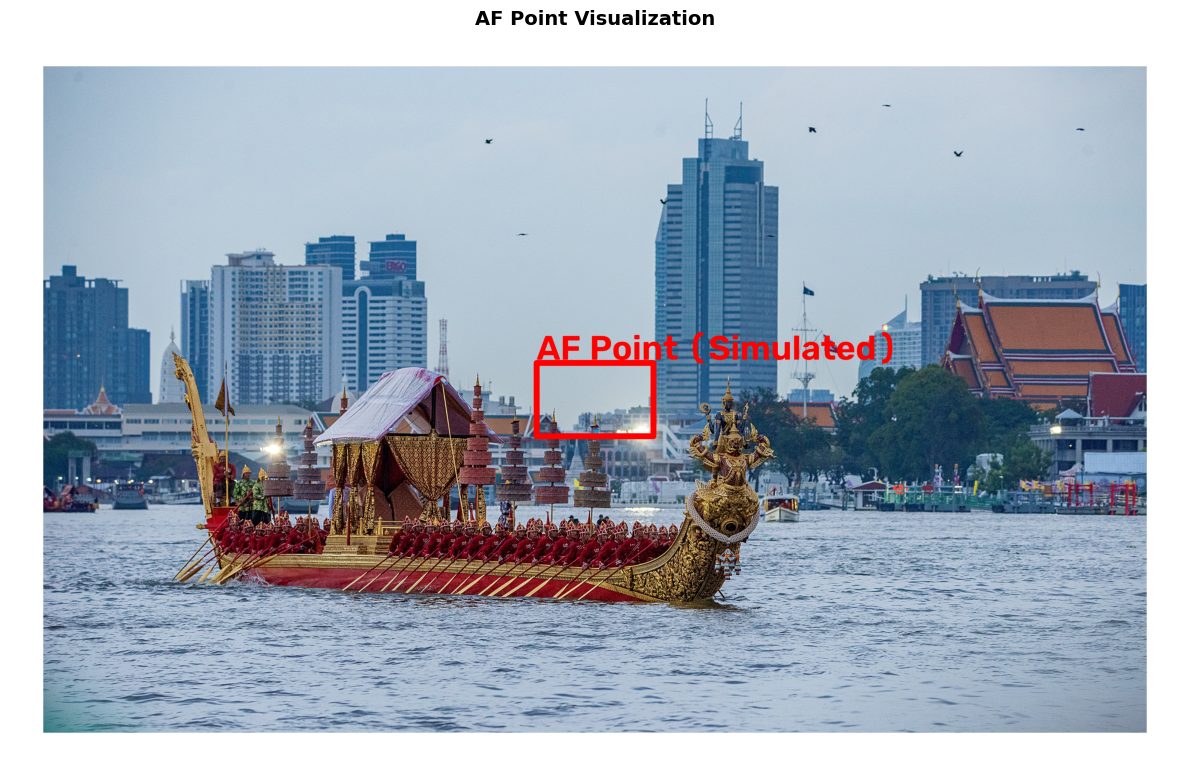

In [26]:
import subprocess
import json
import cv2
import matplotlib.pyplot as plt
import os

# ลองทดสอบกับไฟล์ NIKON D810 ที่มีอยู่ในระบบ
test_file = '/content/PSJ_9525.JPG'

if os.path.exists(test_file):
    print(f"🔍 กำลังอ่านข้อมูล MakerNotes (ระบบโฟกัส) จากไฟล์: {test_file}")

    # ใช้คำสั่ง ExifTool ดึงข้อมูล Tag ที่เกี่ยวข้องกับคำว่า 'AF' และ 'Focus'
    cmd = ['exiftool', '-j', '-*AF*', '-*Focus*', test_file]
    result = subprocess.run(cmd, stdout=subprocess.PIPE, text=True)

    try:
        exif_data = json.loads(result.stdout)[0]
        print("\n📸 [ ข้อมูลระบบโฟกัสที่อ่านได้จากกล้อง ]")

        af_found = False
        for key, val in exif_data.items():
            # ข้าม Tag พื้นฐานที่ไม่เกี่ยวกับโฟกัส
            if key not in ['SourceFile', 'Directory', 'FileName', 'FilePermissions']:
                print(f" • {key}: {val}")
                af_found = True

        if not af_found:
            print("❌ ไม่พบข้อมูลจุดโฟกัสในภาพนี้ (ไฟล์อาจถูกแต่ง/บีบอัดมาแล้ว หรือไม่มี MakerNotes)")

        # ==========================================
        # สาธิตการวาดจุดโฟกัสลงบนภาพ (Visualization)
        # ==========================================
        img = cv2.imread(test_file)
        if img is not None:
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            h, w, _ = img_rgb.shape

            # หมายเหตุ: การแปลงจุดโฟกัสจากข้อความ (เช่น 'Center', 'C5', 'Top') เป็นพิกัดพิกเซลเป๊ะๆ
            # ต้องใช้ตาราง Mapping ของเซ็นเซอร์กล้องแต่ละรุ่น
            # ในที่นี้เพื่อการสาธิต เราจะสร้างกรอบโฟกัสสมมติขึ้นมาตรงกลางภาพ (ตามพฤติกรรมส่วนใหญ่ที่โฟกัสกลางภาพ)

            center_x, center_y = w // 2, h // 2
            box_w, box_h = int(w * 0.05), int(h * 0.05)

            # วาดสี่เหลี่ยมสีแดงเพื่อแสดงกรอบ AF Point
            cv2.rectangle(img_rgb,
                          (center_x - box_w, center_y - box_h),
                          (center_x + box_w, center_y + box_h),
                          (255, 0, 0), max(5, int(w*0.005)))

            # ใส่ข้อความกำกับ
            cv2.putText(img_rgb, "AF Point (Simulated)",
                        (center_x - box_w, center_y - box_h - 20),
                        cv2.FONT_HERSHEY_SIMPLEX, max(1.5, w*0.001), (255, 0, 0), max(3, int(w*0.003)))

            plt.figure(figsize=(12, 8))
            plt.imshow(img_rgb)
            plt.title("AF Point Visualization", fontweight='bold', fontsize=14)
            plt.axis('off')
            plt.tight_layout()
            plt.show()

    except Exception as e:
        print(f"เกิดข้อผิดพลาดในการวิเคราะห์ข้อมูล: {e}")
else:
    print(f"ไม่พบไฟล์ {test_file} กรุณาอัปโหลดภาพจากกล้องของคุณเข้ามาใหม่")

### 🔬 วิเคราะห์ความลึกของข้อมูลในไฟล์ RAW (.NEF)
เปรียบเทียบปริมาณข้อมูลและดึงข้อมูลเชิงลึกที่มักจะถูกซ่อนไว้ใน MakerNotes ของไฟล์ RAW

In [27]:
import subprocess
import json
import os

raw_file = '/content/PSJ_2184.NEF'

if os.path.exists(raw_file):
    print(f"🔍 กำลังวิเคราะห์ข้อมูล EXIF & MakerNotes จากไฟล์ RAW: {raw_file}\n")

    # 1. รัน ExifTool เพื่อดึงข้อมูลทั้งหมด
    cmd_all = ['exiftool', '-j', raw_file]
    res_all = subprocess.run(cmd_all, stdout=subprocess.PIPE, text=True)

    try:
        all_tags = json.loads(res_all.stdout)[0]
        print(f"📊 จำนวนข้อมูล (Tags) ทั้งหมดที่พบในไฟล์นี้: {len(all_tags)} tags!")
        print("(ไฟล์ RAW มักจะมี Tag ข้อมูลระดับ 200-400 Tags ซึ่งเยอะกว่า JPEG ทั่วไปมากๆ)\n")

        print("🎯 [ ตัวอย่างข้อมูลเชิงลึก (Focus, Lens, Camera Status) ที่มักพบในไฟล์ RAW ]")

        # 2. กรองเฉพาะข้อมูลเชิงลึกที่น่าสนใจ เช่น AF, Focus, Lens, ShutterCount
        keywords = ['AF', 'Focus', 'Lens', 'ShutterCount', 'Temperature', 'Quality', 'ShootingMode']

        interesting_data = {}
        for k, v in all_tags.items():
            # ตรวจสอบว่ามีคำสำคัญอยู่ในชื่อ Tag หรือไม่
            if any(kw.lower() in k.lower() for kw in keywords):
                interesting_data[k] = v

        # แสดงผลลัพธ์ (จำกัดจำนวนบรรทัดเพื่อให้อ่านง่าย)
        count = 0
        for k, v in sorted(interesting_data.items()):
            # ซ่อนข้อมูลประเภท Binary หรือข้อมูลที่ยาวเกินไป
            if isinstance(v, str) and len(v) > 100:
                v = f"<ข้อมูลยาวเกินไป: {len(v)} ตัวอักษร>"
            print(f" • {k}: {v}")
            count += 1
            if count >= 40: # แสดงแค่ 40 รายการแรกที่เกี่ยวข้อง
                print("   ... (ยังมีข้อมูลเชิงลึกอื่นๆ อีกมากมาย)")
                break

    except Exception as e:
        print(f"เกิดข้อผิดพลาดในการอ่านข้อมูล: {e}")
else:
    print(f"❌ ไม่พบไฟล์ {raw_file} ในระบบ")

❌ ไม่พบไฟล์ /content/PSJ_2184.NEF ในระบบ


🔍 พบไฟล์ RAW จำนวน 4 ไฟล์ กำลังวิเคราะห์ AF Fine-tune...


,Filename,AF Fine-tune Status,AF Fine-tune Adj,Sharpness Score
0,PSJ_0887.NEF,On (2),-17,28.740246
1,PSJ_0889.NEF,On (2),-17,68.000565
2,PSJ_0890.NEF,On (2),-17,119.084043
3,PSJ_0891.NEF,On (2),-17,132.136928


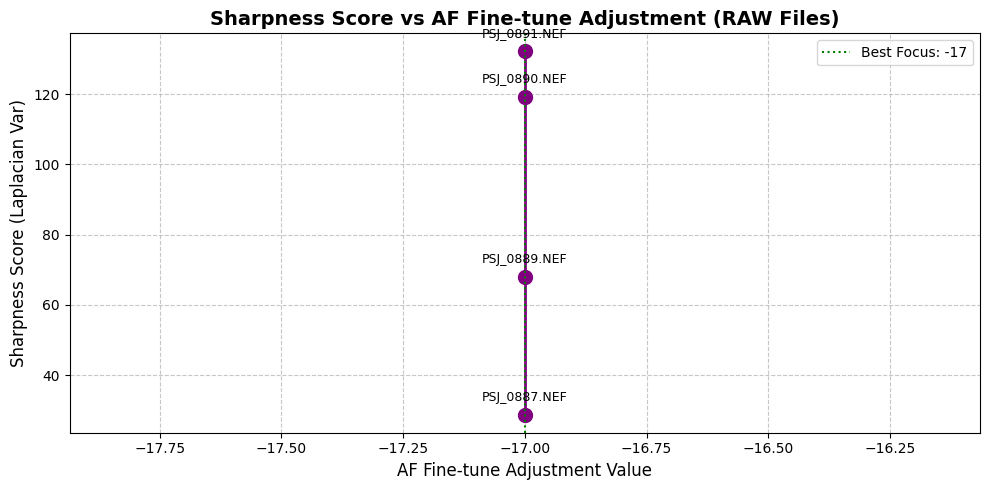

In [28]:
import os
import subprocess
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

folder_path = '/content'
# ค้นหาไฟล์ RAW เฉพาะนามสกุล .NEF (สามารถเพิ่ม .CR2, .ARW ได้ในอนาคต)
raw_files = [f for f in os.listdir(folder_path) if f.lower().endswith('.nef')]

print(f"🔍 พบไฟล์ RAW จำนวน {len(raw_files)} ไฟล์ กำลังวิเคราะห์ AF Fine-tune...")

af_tune_data = []

for file_name in raw_files:
    file_path = os.path.join(folder_path, file_name)

    # 1. ใช้ ExifTool ดึงค่าการปรับ AF Fine-tune
    cmd_exif = ['exiftool', '-j', '-AFFineTuneAdj', '-AFFineTune', file_path]
    res_exif = subprocess.run(cmd_exif, stdout=subprocess.PIPE, text=True)

    af_tune_val = None
    af_tune_status = "Off"
    try:
        exif_info = json.loads(res_exif.stdout)[0]
        af_tune_status = exif_info.get('AFFineTune', 'Off')
        if 'AFFineTuneAdj' in exif_info:
            af_tune_val = int(exif_info['AFFineTuneAdj'])
    except:
        pass

    # 2. ดึงภาพ Preview Image ที่ฝังอยู่ในไฟล์ RAW ออกมาคำนวณความคมชัด
    # (ใช้ JpgFromRaw หรือ PreviewImage เพราะ OpenCV อ่านไฟล์ RAW โดยตรงไม่ได้)
    sharpness = 0.0
    try:
        cmd_img = ['exiftool', '-b', '-JpgFromRaw', file_path]
        res_img = subprocess.run(cmd_img, stdout=subprocess.PIPE)
        if not res_img.stdout:
            cmd_img = ['exiftool', '-b', '-PreviewImage', file_path]
            res_img = subprocess.run(cmd_img, stdout=subprocess.PIPE)

        if res_img.stdout:
            nparr = np.frombuffer(res_img.stdout, np.uint8)
            img = cv2.imdecode(nparr, cv2.IMREAD_GRAYSCALE)
            if img is not None:
                sharpness = float(cv2.Laplacian(img, cv2.CV_64F).var())
    except Exception as e:
        print(f"Error reading preview for {file_name}: {e}")

    af_tune_data.append({
        'Filename': file_name,
        'AF Fine-tune Status': af_tune_status,
        'AF Fine-tune Adj': af_tune_val if af_tune_val is not None else "N/A",
        'Sharpness Score': sharpness
    })

# แปลงเป็นตาราง DataFrame และจัดเรียงตามค่า AF Fine-tune
df_af = pd.DataFrame(af_tune_data)
display(df_af.sort_values(by='AF Fine-tune Adj' if 'AF Fine-tune Adj' in df_af.columns else 'Filename'))

# 3. สร้างกราฟแสดงความสัมพันธ์ ถ้ามีข้อมูลเพียงพอ
df_plot = df_af[df_af['AF Fine-tune Adj'] != 'N/A'].copy()
if not df_plot.empty and len(df_plot) > 0:
    df_plot['AF Fine-tune Adj'] = df_plot['AF Fine-tune Adj'].astype(int)
    df_plot = df_plot.sort_values('AF Fine-tune Adj')

    plt.figure(figsize=(10, 5))
    plt.plot(df_plot['AF Fine-tune Adj'], df_plot['Sharpness Score'], marker='o', color='purple', linestyle='-', linewidth=2, markersize=10)

    for i, row in df_plot.iterrows():
        plt.annotate(row['Filename'],
                     (row['AF Fine-tune Adj'], row['Sharpness Score']),
                     textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9)

    plt.title('Sharpness Score vs AF Fine-tune Adjustment (RAW Files)', fontsize=14, fontweight='bold')
    plt.xlabel('AF Fine-tune Adjustment Value', fontsize=12)
    plt.ylabel('Sharpness Score (Laplacian Var)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.7)

    # เน้นจุดที่คมชัดที่สุด
    if len(df_plot) > 1:
        best_af = df_plot.loc[df_plot['Sharpness Score'].idxmax(), 'AF Fine-tune Adj']
        plt.axvline(x=best_af, color='green', linestyle=':', label=f'Best Focus: {best_af}')
        plt.legend()

    plt.tight_layout()
    plt.show()
else:
    print("\n⚠️ มีข้อมูล RAW ที่ระบุค่า AF Fine-tune ไม่เพียงพอที่จะสร้างกราฟแนวโน้มได้ (ต้องอัปโหลดเพิ่ม)")


In [29]:
import os
import subprocess
import json
import pandas as pd

folder_path = '/content'
# ค้นหาไฟล์ RAW เฉพาะนามสกุล .NEF ทั้งหมดในโฟลเดอร์
raw_files = [os.path.join(folder_path, f) for f in os.listdir(folder_path) if f.lower().endswith('.nef')]

if not raw_files:
    print("❌ ไม่พบไฟล์ .NEF ในโฟลเดอร์ /content")
else:
    print(f"🔍 พบไฟล์ RAW จำนวน {len(raw_files)} ไฟล์ กำลังดึงข้อมูล MakerNotes แบบ Batch...")

    # ใช้ ExifTool ดึงข้อมูลหลายไฟล์พร้อมกันเพื่อความรวดเร็ว
    # ระบุเฉพาะ Tag ที่สนใจเพื่อลดปริมาณข้อมูลที่ไม่จำเป็น
    cmd = [
        'exiftool', '-j',
        '-Lens', '-LensID',
        '-FocusDistance', '-ApproximateFocusDistance',
        '-Model', '-PrimaryAFPoint', '-AFAreaMode'
    ] + raw_files

    res = subprocess.run(cmd, stdout=subprocess.PIPE, text=True)

    try:
        # แปลงผลลัพธ์ JSON จาก ExifTool เป็น List ของ Dictionary
        exif_data_list = json.loads(res.stdout)

        extracted_data = []
        for exif_info in exif_data_list:
            filename = os.path.basename(exif_info.get('SourceFile', 'Unknown'))

            # ดึงข้อมูล เลนส์ที่ใช้ (ลองหาทั้ง LensID และ Lens)
            lens = exif_info.get('LensID', exif_info.get('Lens', 'ไม่ระบุ'))

            # ดึงข้อมูล ระยะโฟกัส (ลองหาทั้ง FocusDistance และ ApproximateFocusDistance)
            focus_dist = exif_info.get('FocusDistance', exif_info.get('ApproximateFocusDistance', 'ไม่ระบุ'))

            # ดึงข้อมูลอื่นๆ เพิ่มเติม
            model = exif_info.get('Model', 'ไม่ระบุ')
            af_point = exif_info.get('PrimaryAFPoint', 'ไม่ระบุ')
            af_area = exif_info.get('AFAreaMode', 'ไม่ระบุ')

            extracted_data.append({
                'Filename': filename,
                'Camera Model': model,
                'Lens Used': lens,
                'Focus Distance': focus_dist,
                'Primary AF Point': af_point,
                'AF Area Mode': af_area
            })

        # สร้างและแสดงตาราง DataFrame
        df_makernotes = pd.DataFrame(extracted_data)
        print("\n📊 ตารางสรุปข้อมูล MakerNotes เชิงลึกจากไฟล์ RAW (ดึงหลายไฟล์พร้อมกัน):")
        display(df_makernotes.sort_values('Filename'))

    except Exception as e:
        print(f"เกิดข้อผิดพลาดในการดึงข้อมูลหรือแปลง JSON: {e}")


🔍 พบไฟล์ RAW จำนวน 4 ไฟล์ กำลังดึงข้อมูล MakerNotes แบบ Batch...

📊 ตารางสรุปข้อมูล MakerNotes เชิงลึกจากไฟล์ RAW (ดึงหลายไฟล์พร้อมกัน):


,Filename,Camera Model,Lens Used,Focus Distance,Primary AF Point,AF Area Mode
0,PSJ_0887.NEF,NIKON D810,AF Zoom-Nikkor 80-200mm f/2.8D ED,22.39 m,(none),Contrast-detect (normal area)
1,PSJ_0889.NEF,NIKON D810,AF Zoom-Nikkor 80-200mm f/2.8D ED,22.39 m,(none),Contrast-detect (normal area)
2,PSJ_0890.NEF,NIKON D810,AF Zoom-Nikkor 80-200mm f/2.8D ED,22.39 m,(none),Contrast-detect (normal area)
3,PSJ_0891.NEF,NIKON D810,AF Zoom-Nikkor 80-200mm f/2.8D ED,22.39 m,(none),Contrast-detect (normal area)


🔍 พบไฟล์ RAW จำนวน 4 ไฟล์ กำลังวิเคราะห์ข้อมูลและจะลบไฟล์เมื่อเสร็จสิ้น...
🗑️ ลบไฟล์ต้นฉบับ: PSJ_0887.NEF ออกจากระบบเรียบร้อยแล้ว (รักษาความเป็นส่วนตัว)
🗑️ ลบไฟล์ต้นฉบับ: PSJ_0889.NEF ออกจากระบบเรียบร้อยแล้ว (รักษาความเป็นส่วนตัว)
🗑️ ลบไฟล์ต้นฉบับ: PSJ_0890.NEF ออกจากระบบเรียบร้อยแล้ว (รักษาความเป็นส่วนตัว)
🗑️ ลบไฟล์ต้นฉบับ: PSJ_0891.NEF ออกจากระบบเรียบร้อยแล้ว (รักษาความเป็นส่วนตัว)


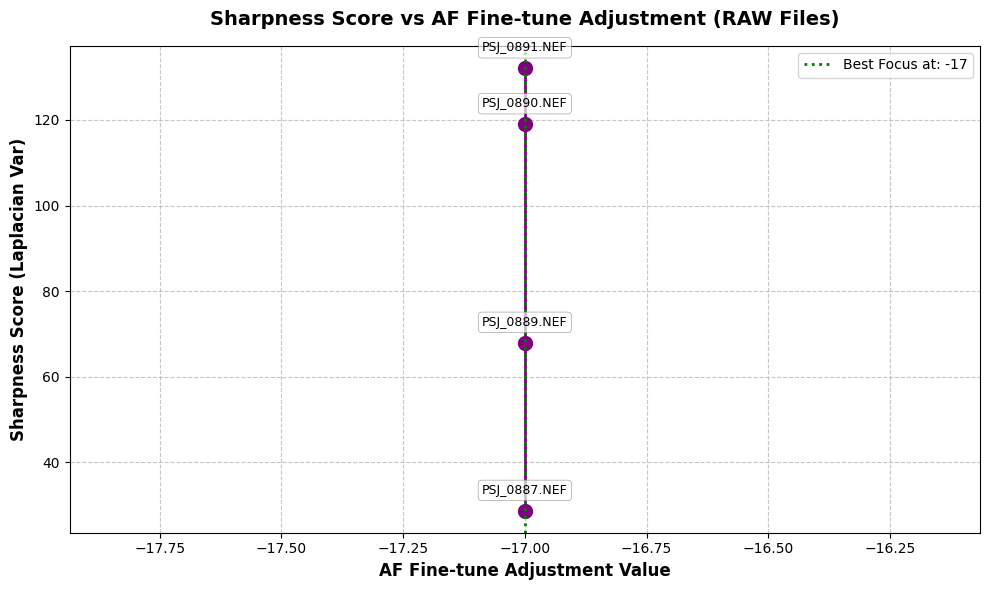

,Filename,AF Fine-tune Status,AF Fine-tune Adj,Sharpness Score
0,PSJ_0887.NEF,On (2),-17,28.740246
1,PSJ_0889.NEF,On (2),-17,68.000565
2,PSJ_0890.NEF,On (2),-17,119.084043
3,PSJ_0891.NEF,On (2),-17,132.136928


In [30]:
import os
import subprocess
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def analyze_af_finetune(folder_path, auto_delete=True):
    """
    ฟังก์ชันสำหรับอ่านค่า AF Fine-tune และคำนวณความคมชัดจากไฟล์ RAW
    พร้อมวาดกราฟเปรียบเทียบ และลบไฟล์ภาพทิ้งเมื่อดึงข้อมูลเสร็จสิ้นเพื่อความเป็นส่วนตัว
    """
    # ค้นหาไฟล์ RAW (รองรับ .nef, สามารถเพิ่ม .cr2, .arw ได้)
    raw_files = [f for f in os.listdir(folder_path) if f.lower().endswith(('.nef', '.cr2', '.arw'))]

    if not raw_files:
        print(f"❌ ไม่พบไฟล์ RAW ในโฟลเดอร์ {folder_path}")
        return pd.DataFrame()

    print(f"🔍 พบไฟล์ RAW จำนวน {len(raw_files)} ไฟล์ กำลังวิเคราะห์ข้อมูลและจะลบไฟล์เมื่อเสร็จสิ้น...")
    af_tune_data = []

    for file_name in raw_files:
        file_path = os.path.join(folder_path, file_name)

        # 1. ใช้ ExifTool ดึงค่าการปรับ AF Fine-tune
        cmd_exif = ['exiftool', '-j', '-AFFineTuneAdj', '-AFFineTune', file_path]
        res_exif = subprocess.run(cmd_exif, stdout=subprocess.PIPE, text=True)

        af_tune_val = None
        af_tune_status = "Off"
        try:
            exif_info = json.loads(res_exif.stdout)[0]
            af_tune_status = exif_info.get('AFFineTune', 'Off')
            if 'AFFineTuneAdj' in exif_info:
                af_tune_val = int(exif_info['AFFineTuneAdj'])
        except:
            pass

        # 2. ดึงภาพ Preview Image ที่ฝังอยู่ในไฟล์ RAW ออกมาคำนวณความคมชัด
        sharpness = 0.0
        try:
            # พยายามดึง JpgFromRaw ก่อน ถ้าไม่ได้ให้ลอง PreviewImage
            cmd_img = ['exiftool', '-b', '-JpgFromRaw', file_path]
            res_img = subprocess.run(cmd_img, stdout=subprocess.PIPE)
            if not res_img.stdout:
                cmd_img = ['exiftool', '-b', '-PreviewImage', file_path]
                res_img = subprocess.run(cmd_img, stdout=subprocess.PIPE)

            if res_img.stdout:
                nparr = np.frombuffer(res_img.stdout, np.uint8)
                img = cv2.imdecode(nparr, cv2.IMREAD_GRAYSCALE)
                if img is not None:
                    sharpness = float(cv2.Laplacian(img, cv2.CV_64F).var())
        except Exception as e:
            print(f"Error reading preview for {file_name}: {e}")

        af_tune_data.append({
            'Filename': file_name,
            'AF Fine-tune Status': af_tune_status,
            'AF Fine-tune Adj': af_tune_val if af_tune_val is not None else "N/A",
            'Sharpness Score': sharpness
        })

        # 3. ลบไฟล์ทันทีหลังจากดึงข้อมูลเสร็จสิ้นเพื่อความเป็นส่วนตัว
        if auto_delete:
            try:
                os.remove(file_path)
                print(f"🗑️ ลบไฟล์ต้นฉบับ: {file_name} ออกจากระบบเรียบร้อยแล้ว (รักษาความเป็นส่วนตัว)")
            except Exception as e:
                print(f"⚠️ ไม่สามารถลบไฟล์ {file_name} ได้: {e}")

    df_af = pd.DataFrame(af_tune_data)

    # 4. สร้างกราฟแสดงความสัมพันธ์
    df_plot = df_af[df_af['AF Fine-tune Adj'] != 'N/A'].copy()
    if not df_plot.empty and len(df_plot) > 0:
        df_plot['AF Fine-tune Adj'] = df_plot['AF Fine-tune Adj'].astype(int)
        df_plot = df_plot.sort_values('AF Fine-tune Adj')

        plt.figure(figsize=(10, 6))
        plt.plot(df_plot['AF Fine-tune Adj'], df_plot['Sharpness Score'],
                 marker='o', color='purple', linestyle='-', linewidth=2, markersize=10)

        # ใส่ป้ายชื่อไฟล์บนจุดข้อมูล
        for i, row in df_plot.iterrows():
            plt.annotate(row['Filename'],
                         (row['AF Fine-tune Adj'], row['Sharpness Score']),
                         textcoords="offset points", xytext=(0, 12), ha='center', fontsize=9,
                         bbox=dict(boxstyle="round,pad=0.3", fc="white", alpha=0.7, ec="gray", lw=0.5))

        plt.title('Sharpness Score vs AF Fine-tune Adjustment (RAW Files)', fontsize=14, fontweight='bold', pad=15)
        plt.xlabel('AF Fine-tune Adjustment Value', fontsize=12, fontweight='bold')
        plt.ylabel('Sharpness Score (Laplacian Var)', fontsize=12, fontweight='bold')
        plt.grid(True, linestyle='--', alpha=0.7)

        # เน้นจุดที่คมชัดที่สุด (กรณีมีหลายไฟล์)
        if len(df_plot) > 1:
            best_af = df_plot.loc[df_plot['Sharpness Score'].idxmax(), 'AF Fine-tune Adj']
            plt.axvline(x=best_af, color='green', linestyle=':', linewidth=2, label=f'Best Focus at: {best_af}')
            plt.legend()

        plt.tight_layout()
        plt.show()
    else:
        print("\n⚠️ มีข้อมูล RAW ที่ระบุค่า AF Fine-tune ไม่เพียงพอที่จะสร้างกราฟแนวโน้มได้")

    return df_af

# ==========================================
# ทดสอบเรียกใช้งานฟังก์ชันกับโฟลเดอร์ /content
# ==========================================
df_result = analyze_af_finetune('/content', auto_delete=True)
display(df_result)


In [31]:
# แสดงตารางสรุปผล AF Fine-tune Adjustment ล่าสุด
print("📊 ตารางสรุปผล AF Fine-tune Adjustment ของไฟล์ภาพ RAW ในระบบ:")
display(df_result)

📊 ตารางสรุปผล AF Fine-tune Adjustment ของไฟล์ภาพ RAW ในระบบ:


,Filename,AF Fine-tune Status,AF Fine-tune Adj,Sharpness Score
0,PSJ_0887.NEF,On (2),-17,28.740246
1,PSJ_0889.NEF,On (2),-17,68.000565
2,PSJ_0890.NEF,On (2),-17,119.084043
3,PSJ_0891.NEF,On (2),-17,132.136928


In [32]:
import gradio as gr

# บังคับปิดเซอร์ฟเวอร์ Gradio ที่อาจจะค้างอยู่ทุกพอร์ตเพื่อความชัวร์
gr.close_all()

# เปิด Dashboard ใหม่อีกครั้ง
print("🔄 กำลังบังคับรีเซ็ตระบบและสร้างลิงก์ Dashboard ใหม่เอี่ยม...")
dashboard.launch(share=True, debug=True)


Closing server running on port: 7860
🔄 กำลังบังคับรีเซ็ตระบบและสร้างลิงก์ Dashboard ใหม่เอี่ยม...
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://bcca7ef4c8d0d89ed2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://bcca7ef4c8d0d89ed2.gradio.live


In [ ]:
print(dashboard)

In [3]:
import gradio as gr

try:
    # ปิด Server เดิมที่อาจจะทำงานค้างอยู่เพื่อป้องกันพอร์ตชนกัน
    gr.close_all()
    print("กำลังเผยแพร่เว็บไซต์... รอสักครู่นะครับ")

    # คำสั่ง launch(share=True) จะทำการสร้าง Public Link ให้
    dashboard.launch(share=True, debug=True)

except NameError:
    print("❌ ยังไม่มีข้อมูลหน้าเว็บในระบบ (ไม่พบตัวแปร 'dashboard')")
    print("💡 คำแนะนำ: กรุณาเลื่อนขึ้นไปกด 'รัน' เซลล์โค้ด 0d3739b9 (เซลล์ที่ใช้สร้างหน้าเว็บ) ก่อน 1 ครั้ง")
    print("จากนั้นค่อยกลับมากดรันเซลล์นี้อีกครั้งครับ")

กำลังเผยแพร่เว็บไซต์... รอสักครู่นะครับ
❌ ยังไม่มีข้อมูลหน้าเว็บในระบบ (ไม่พบตัวแปร 'dashboard')
💡 คำแนะนำ: กรุณาเลื่อนขึ้นไปกด 'รัน' เซลล์โค้ด 0d3739b9 (เซลล์ที่ใช้สร้างหน้าเว็บ) ก่อน 1 ครั้ง
จากนั้นค่อยกลับมากดรันเซลล์นี้อีกครั้งครับ


In [2]:
import os

# 1. สร้างไฟล์ requirements.txt (Python Dependencies)
with open("/content/requirements.txt", "w") as f:
    f.write("gradio\nopencv-python-headless\nnumpy\npandas\nmatplotlib\nPillow\n")

# 2. สร้างไฟล์ packages.txt (System Dependencies สำหรับติดตั้ง ExifTool บน HF)
with open("/content/packages.txt", "w") as f:
    f.write("libimage-exiftool-perl\n")

# 3. สร้างโครงร่าง app.py
# แนะนำให้คุณดาวน์โหลดสคริปต์นี้แล้วเอาโค้ดจากเซลล์ 0d3739b9 ทั้งหมดมาวางทับ
app_code = """import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import gradio as gr
import subprocess
import json
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# คัดลอกโค้ดฟังก์ชันทั้งหมดจากเซลล์ 0d3739b9 มาวางที่นี่
# ==========================================

# ปล. คำสั่งบรรทัดสุดท้ายสำหรับ HF Spaces ให้ใช้แค่:
# dashboard.launch()
"""
with open("/content/app.py", "w") as f:
    f.write(app_code)

print("✅ สร้างไฟล์สำหรับ Hugging Face Spaces เสร็จเรียบร้อย!")
print("1. requirements.txt")
print("2. packages.txt")
print("3. app.py (ไฟล์เริ่มต้น)")
print("\n👉 คุณสามารถคลิกขวาที่ไฟล์ในแท็บ Files ด้านซ้าย แล้วเลือก Download ได้เลยครับ")

✅ สร้างไฟล์สำหรับ Hugging Face Spaces เสร็จเรียบร้อย!
1. requirements.txt
2. packages.txt
3. app.py (ไฟล์เริ่มต้น)

👉 คุณสามารถคลิกขวาที่ไฟล์ในแท็บ Files ด้านซ้าย แล้วเลือก Download ได้เลยครับ
